# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북의 목표는 그래프를 많이 만드는 것이 아닙니다. **분석 질문에 맞는 그래프를 선택하고, 그래프에 들어간 데이터 범위와 수치를 검증하며, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**이 핵심입니다.

금액성 그래프는 기본적으로 `order_status == "completed"` 범위를 사용합니다. `line_total`은 주문 상세 한 행의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.

## 제출 정보
- 이름: 김지인
- GitHub ID: jiin-0
- 작성일: 2026-10-28
- 최종 Notebook URL: https://github.com/jiin-0/llm-data-analysis-study/blob/main/chapter07/ch07_visualization.ipynb

## 0. 사용 방법

- 위에서부터 차례대로 실행합니다.
- 입력은 Chapter 05에서 만든 `data/processed/*_clean.csv`입니다.
- 파일이 없다면 프로젝트 루트에서 `python scripts/preprocess_data.py`를 먼저 실행합니다.
- 그래프를 보기 전에 **시각화용 집계 검증표**를 먼저 확인합니다.
- 대표 그래프마다 `관찰 → 해석 → 한계 → 다음 질문`을 Markdown 셀에 직접 작성합니다.
- 실제 실행 결과 숫자를 보고 작성하며 강의안의 예시를 정답처럼 사용하지 않습니다.

## 1. 질문에 맞는 그래프를 먼저 고릅니다

| 분석 질문 | 그래프 | 데이터 범위 |
| --- | --- | --- |
| 카테고리별 완료 주문 금액은 어떻게 다른가? | 막대그래프 | completed 주문 상세 |
| 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | completed + 유효한 주문일 |
| 상품 가격은 어느 구간에 몰려 있는가? | 히스토그램 | 전체 상품 마스터 |
| 상품 가격과 완료 주문 판매 수량은 어떤 패턴인가? | 산점도 | completed 상품 집계 |
| 완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가? | 가로 막대그래프 | completed 고객 집계 |
| 주문 상태별 주문 수는 어떻게 다른가? | 막대그래프 | 전체 orders |

> 그래프 종류보다 먼저 **질문과 데이터 범위**를 고정합니다.

## 1. 시각화 질문과 그래프 선택
| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 요일별 완료 주문 금액은 어떻게 변하는가? | 막대 그래프 | 요일에 따른 금액 차이를 시각화하여 나타내 현재 판매 추이를 직관적으로 이해하고자함. |
| 상품 가격의 분포는 어떠한가? | 히스토그램 | 가격 분포를 고려하여 신상품 출시 시 금액대를 설정하고자함. |
| 성별에 따른 완료 주문 금액은 어떻게 다른가? | 원 그래프 | 성별에 따른 완료 주문 금액을 조사하여 마케팅 근거 자료로 쓰고자함 |

In [1]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("현재 실행 위치:", CURRENT_DIR)
print("프로젝트 루트:", PROJECT_ROOT)
print("전처리 데이터 폴더:", PROCESSED_DIR)
print("그래프 저장 폴더:", FIGURE_DIR)

현재 실행 위치: c:\dev\llm-data-analysis-study\notebooks
프로젝트 루트: c:\dev\llm-data-analysis-study
전처리 데이터 폴더: c:\dev\llm-data-analysis-study\data\processed
그래프 저장 폴더: c:\dev\llm-data-analysis-study\reports\figures


## 2. 검증된 시각화용 데이터를 준비합니다

공통 모듈은 그래프를 그리기 전에 다음을 검사합니다.

- 필수 컬럼
- PK 결측·중복
- `many_to_one` 병합
- 주문/상품 미매칭
- 숫자형 변환 실패
- `completed` 주문 범위
- 카테고리·상품·고객·월별 집계 총합

문제가 있으면 그래프를 만들기 전에 중단합니다.

In [2]:
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

viz_data = prepare_visualization_data(PROCESSED_DIR)

products = viz_data["products"]
orders = viz_data["orders"]
completed_order_sales = viz_data["completed_order_sales"]
category_sales = viz_data["category_sales"]
monthly_sales = viz_data["monthly_sales"]
product_sales = viz_data["product_sales"]
customer_sales = viz_data["customer_sales"]
order_status = viz_data["order_status"]

print("완료 주문 상세 행:", len(completed_order_sales))
print(
    "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"]),
)

사용 한글 폰트: Malgun Gothic
완료 주문 상세 행: 424
월별 집계에서 제외되는 날짜 결측 완료 주문 상세: 0


In [16]:
viz_data["visualization_validation"]

,check,expected,actual,difference,passed
0,category_completed_amount,135422000.0,135422000.0,0.0,True
1,product_completed_amount,135422000.0,135422000.0,0.0,True
2,customer_completed_amount,135422000.0,135422000.0,0.0,True
3,monthly_completed_amount_valid_dates,135422000.0,135422000.0,0.0,True


In [22]:
viz_data["orders"]

,order_id,customer_id,order_date,payment_method,order_status,order_month,order_dayofweek
0,1,144,2026-07-12,naver_pay,completed,2026-07,Sunday
1,2,149,2025-10-02,kakao_pay,completed,2025-10,Thursday
2,3,34,2026-03-13,naver_pay,completed,2026-03,Friday
3,4,92,2025-10-12,kakao_pay,completed,2025-10,Sunday
4,5,6,2026-04-17,bank_transfer,cancelled,2026-04,Friday
...,...,...,...,...,...,...,...
292,296,92,2026-04-13,card,completed,2026-04,Monday
293,297,36,2026-07-24,naver_pay,completed,2026-07,Friday
294,298,31,2026-03-27,naver_pay,completed,2026-03,Friday
295,299,133,2026-01-08,naver_pay,cancelled,2026-01,Thursday


In [26]:
order_items=viz_data["order_items"]

In [44]:
# 과제용
day_orders=orders[orders["order_status"]=="completed"].merge(
    order_items,
    on='order_id'
).groupby('order_dayofweek', as_index=False).agg(
    total_sales=('line_total','sum')
)

day_orders.head(7)

,order_dayofweek,total_sales
0,Friday,24467000.0
1,Monday,19758000.0
2,Saturday,11839000.0
3,Sunday,13957000.0
4,Thursday,21742000.0
5,Tuesday,18946000.0
6,Wednesday,24713000.0


### 검증 결과 기록

`passed`가 모두 `True`인지 확인한 뒤 아래 내용을 자신의 말로 작성합니다.

- 총합 검증 결과: 최종적으로 True이다.
- 문제가 있었다면 원인: clean 파일이 실제 clean하지 않아, 파일 간 연결이 완전하지 않았다. 그래서 clean file을 수정하였다.
- 시각화를 진행해도 된다고 판단한 이유: clean file을 수정하여 키가 연결되지 않은 부분들은 시각화 대상에서 제외하였다. 전처리 전에 분석 목표가 설정되어있었다면, 합리적인 처리를 진행하였겠지만, 목표가 불분명하였으므로, 현재 연습 단계의 시각화에서는 과감히 제외하였다.

## 3. 카테고리별 완료 주문 금액 — 막대그래프

범주별 크기 비교이므로 막대그래프를 사용합니다. 값 축은 0에서 시작합니다. 금액이 크다는 사실만으로 선호도가 높다고 단정하지 않습니다.

In [4]:
from src.visualization import plot_category_sales

category_sales[["category", "total_quantity", "completed_amount", "amount_ratio_pct"]]

,category,total_quantity,completed_amount,amount_ratio_pct
9,패션,290.0,32940000.0,24.32
6,식품,220.0,24687000.0,18.23
8,전자기기,167.0,20340000.0,15.02
0,도서,171.0,17441000.0,12.88
2,뷰티,167.0,16915000.0,12.49
5,스포츠,165.0,13237000.0,9.77
4,생활용품,108.0,7001000.0,5.17
3,생활 용품,17.0,2108000.0,1.56
1,뷰 티,12.0,648000.0,0.48
7,전자 기기,5.0,105000.0,0.08


In [42]:
# 과제용
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd

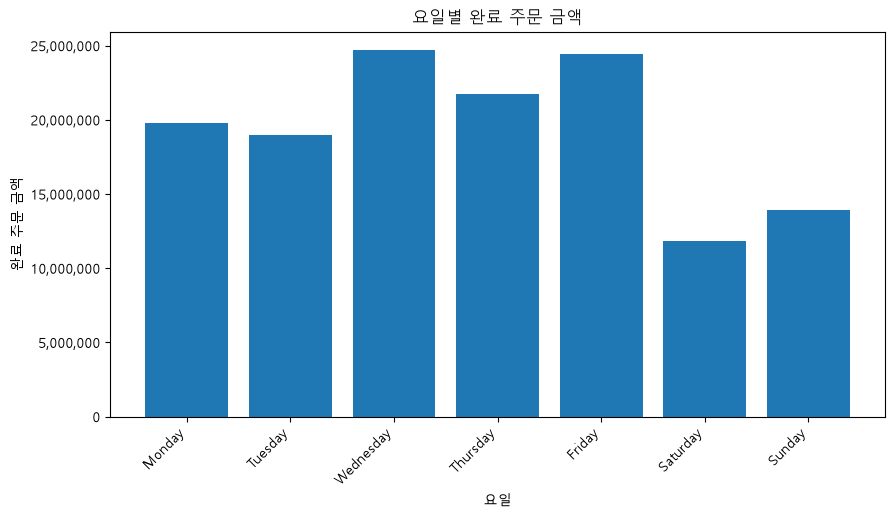

In [43]:
# 과제용
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_orders["order_dayofweek"] = pd.Categorical(day_orders["order_dayofweek"], categories=days, ordered=True)
day_orders = day_orders.sort_values("order_dayofweek")

fig, ax= plt.subplots(figsize=(10,5))
ax.bar(day_orders["order_dayofweek"], day_orders["total_sales"])
ax.set_title("요일별 완료 주문 금액")
ax.set_xlabel("요일")
ax.set_ylabel("완료 주문 금액")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))
ax.tick_params(axis="x", rotation=45)
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")


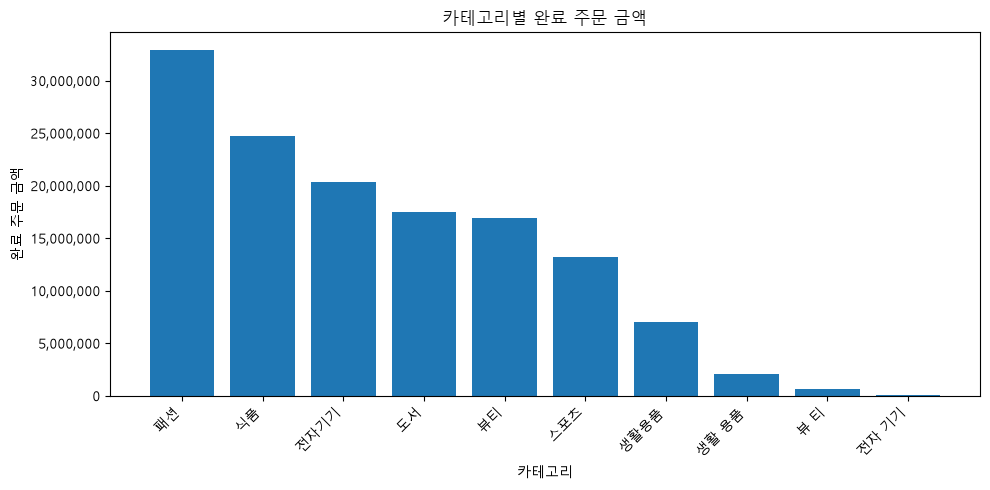

WindowsPath('c:/dev/llm-data-analysis-study/reports/figures/ch07_category_completed_amount_bar.png')

In [5]:
category_path = plot_category_sales(
    category_sales,
    FIGURE_DIR / "ch07_category_completed_amount_bar.png",
    show=True,
)
category_path

### 그래프 1 기록

- **관찰:** 실제 그래프와 집계표에서 직접 확인한 사실
- **해석:** 이 차이가 의미할 수 있는 내용
- **한계:** 금액만으로 알 수 없는 것
- **다음 질문:** 판매 수량·단가·상품 수 중 무엇을 더 확인할 것인가?

## 2. 대표 그래프 1
![대표 그래프 1](images/graph01.png)

### 원본 집계값
월: 19758000
화: 18946000
수: 24713000
목: 21742000
금: 24467000
토: 11839000
일: 13957000

### 결과 관찰
각 요일별 완료 주문 금액이 그래프로 표현되었다. 다른 요일 대비 토요일과 일요일에 판매량이 떨어지는 것이 시각적으로 나타났다.


### 나의 해석과 판단
토요일과 일요일은 주말이므로, 주말 판매량이 평일 대비 낮은 것이 시각적으로 드러났다.

### 업무·분석적 의미
주말에 판매량이 적어지므로, 주말을 타겟하는 마케팅을 진행할 수 있다. 혹은 반대로 판매가 많은 평일에 할인 이벤트를 더해 사람들이 구매시 더 많이 구매하도록 유도 할 수 있다.

### 한계와 추가 확인 사항
실제 할인 이벤트가 존재해서 다른 날들이 뻥튀기가 되었다거나, 영업상의 휴일로 주말에 주문을 받지 않았을 수 있다. 따라서 데이터 외적인 영역의 확인이 필요하다.

## 4. 월별 완료 주문 금액 — 선그래프

시간 순서가 핵심인 질문이므로 선그래프를 사용합니다. 첫 달과 마지막 달이 완전한 한 달인지, 중간 월이 비어 있다면 실제 0인지 데이터 누락인지 확인합니다.

In [6]:
from src.visualization import plot_monthly_sales

monthly_sales[
    [
        "order_month",
        "completed_amount",
        "completed_order_count",
        "average_completed_order_amount",
    ]
]

,order_month,completed_amount,completed_order_count,average_completed_order_amount
0,2025-07,9479000.0,11,861727.0
1,2025-08,8892000.0,17,523059.0
2,2025-09,4519000.0,4,1129750.0
3,2025-10,12547000.0,17,738059.0
4,2025-11,9163000.0,16,572688.0
5,2025-12,8113000.0,12,676083.0
6,2026-01,8135000.0,9,903889.0
7,2026-02,7689000.0,12,640750.0
8,2026-03,7107000.0,13,546692.0
9,2026-04,11459000.0,14,818500.0


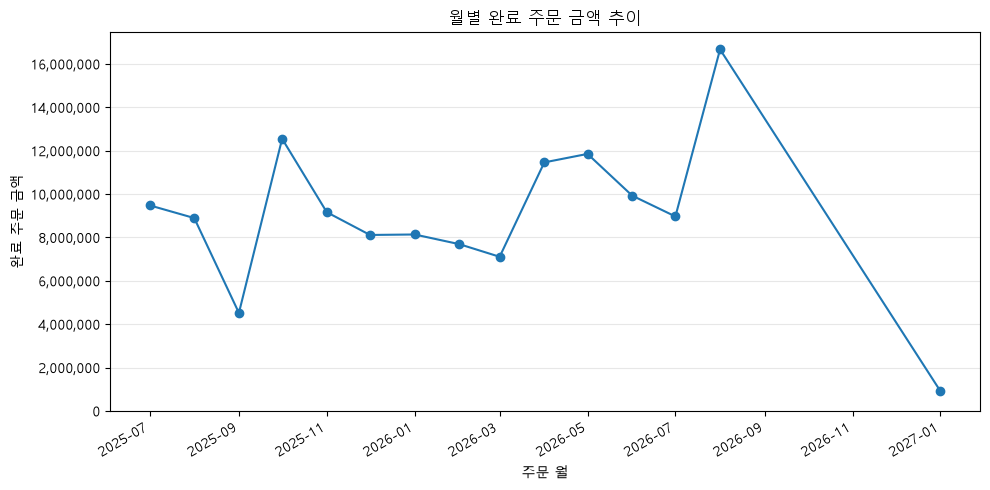

WindowsPath('c:/dev/llm-data-analysis-study/reports/figures/ch07_monthly_completed_amount_line.png')

In [7]:
monthly_path = plot_monthly_sales(
    monthly_sales,
    FIGURE_DIR / "ch07_monthly_completed_amount_line.png",
    show=True,
)
monthly_path

In [48]:
# 성별에 따른 완료 주문 금액
customers=viz_data["customers"]

gender_sales=customers.merge(
    completed_order_sales,
    on='customer_id',
    how='left'
).groupby('gender', as_index=False).agg(
    total_sales=('line_total', 'sum')
)
gender_sales.head()

,gender,total_sales
0,F,74809000.0
1,M,60237000.0


Text(0.5, 1.0, '성별별 완료 주문 금액')

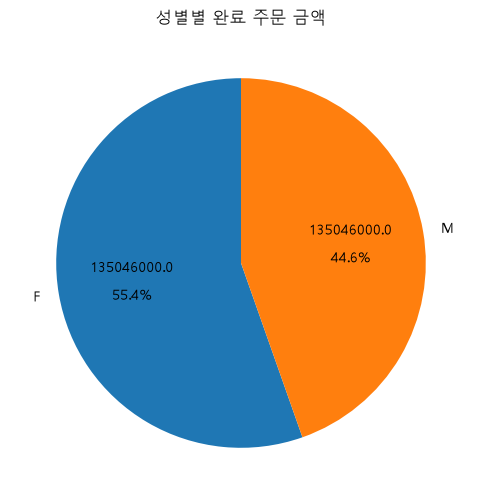

In [62]:
labels = gender_sales["gender"]
sizes = gender_sales["total_sales"]

fig, ax= plt.subplots(figsize=(6,6))
ax.pie(
    sizes,
    labels=labels,
    autopct=f"{sum(sizes)}\n\n{'%1.1f%%'}", 
    startangle=90,  
)
ax.set_title("성별별 완료 주문 금액")

### 그래프 2 기록

- **관찰:** 증가·감소 또는 변곡이 실제로 보이는가?
- **해석:** 주문 수와 평균 주문 금액 중 무엇이 함께 변했는가?
- **한계:** 프로모션·계절성 등 현재 데이터에 없는 원인을 단정하지 않았는가?
- **다음 질문:** 추가로 확인할 지표는 무엇인가?

## 3. 대표 그래프 2
![대표 그래프 2](images/graph02.png)

### 원본 집계값
Female: 74809000
Male: 60237000

### 결과 관찰
여성과 남성의 완료 주문 금액의 차지 비율은 55%와 약 45%로 백분율상 거의 유사하게 나타났다.

### 나의 해석과 판단
여성과 남성의 주문 완료 금액 차이를 비교하고자 함에 있어 원그래프가 적절하다고 생각했고, 그래프로 나타낸 결과 비율을 확인할 수 있어 적합하다고 판단했다.

### 업무·분석적 의미
여성과 남성의 완료 주문 금액을 비교하여, 주고객층을 분석하거나 마케팅 전략을 수립하고자하였다. 그러나 비율이 유사하므로, 한쪽 성별에게 판매량이 치우치지 않고 있다. 따라서 앞으로 기업 계획을 세울 때도 현재의 균형을 인지하여 특정 성별에 치우치지 않도록 신경쓸 필요가 있다.

### 한계와 추가 확인 사항
금액이 양적으로 유사한 것은 맞으나 주문 수나 상품수에 있어서는 차이가 존재할 수 있다. 따라서 총 주문 수나 주문 상품수를 기준으로 추가 비교를 해보면 유용하다

## 5. 상품 가격 분포 — 히스토그램

상품 가격은 상품 마스터의 속성이므로 주문 상태와 무관하게 전체 상품을 봅니다. `bins` 값에 따라 모양이 달라질 수 있으므로 구간 수 하나만 보고 이상값을 확정하지 않습니다.

In [8]:
from src.visualization import plot_product_price_hist

products["price"].describe()

count    9.600000e+01
mean     2.048958e+05
std      1.011848e+06
min      5.000000e+03
25%      5.275000e+04
50%      9.450000e+04
75%      1.532500e+05
max      9.999999e+06
Name: price, dtype: float64

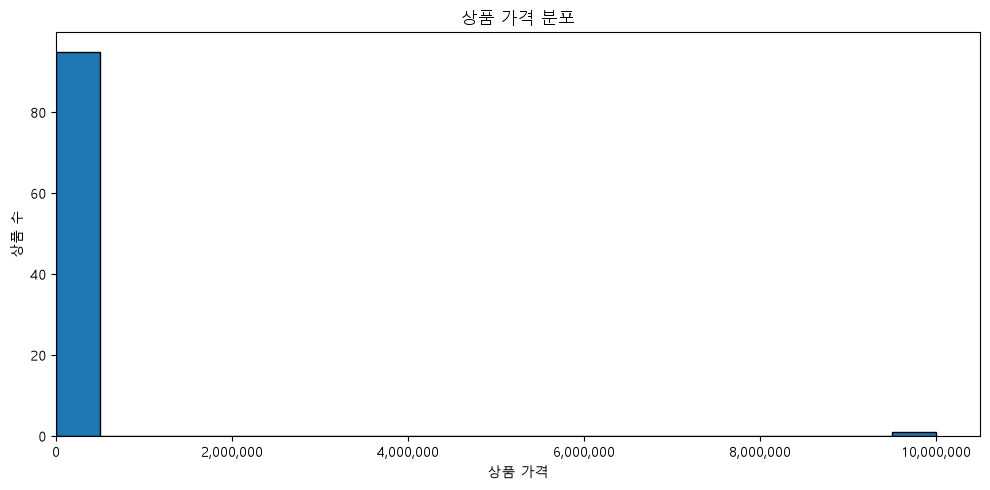

WindowsPath('c:/dev/llm-data-analysis-study/reports/figures/ch07_product_price_hist.png')

In [9]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=20,
)
price_hist_path

### bins 비교 실습

`bins=10`, `20`, `30`으로 바꾸어 같은 데이터가 어떻게 다르게 보이는지 비교합니다.

- 어떤 공통 패턴이 유지되는가?
- 어떤 인상은 bins 선택에 따라 달라지는가?

## 6. 상품 가격과 완료 주문 판매 수량 — 산점도

한 점은 상품 하나입니다. 관계가 보여도 **가격이 판매 수량의 원인**이라고 단정하지 않습니다.

In [10]:
from src.visualization import plot_price_quantity_scatter

product_sales[["price", "completed_quantity", "completed_amount"]].head(10)

,price,completed_quantity,completed_amount
70,183000.0,37.0,6771000.0
90,96000.0,70.0,6720000.0
91,187000.0,26.0,4862000.0
61,193000.0,22.0,4246000.0
50,152000.0,26.0,3952000.0
66,168000.0,21.0,3528000.0
45,171000.0,19.0,3249000.0
36,172000.0,17.0,2924000.0
47,183000.0,15.0,2745000.0
81,145000.0,18.0,2610000.0


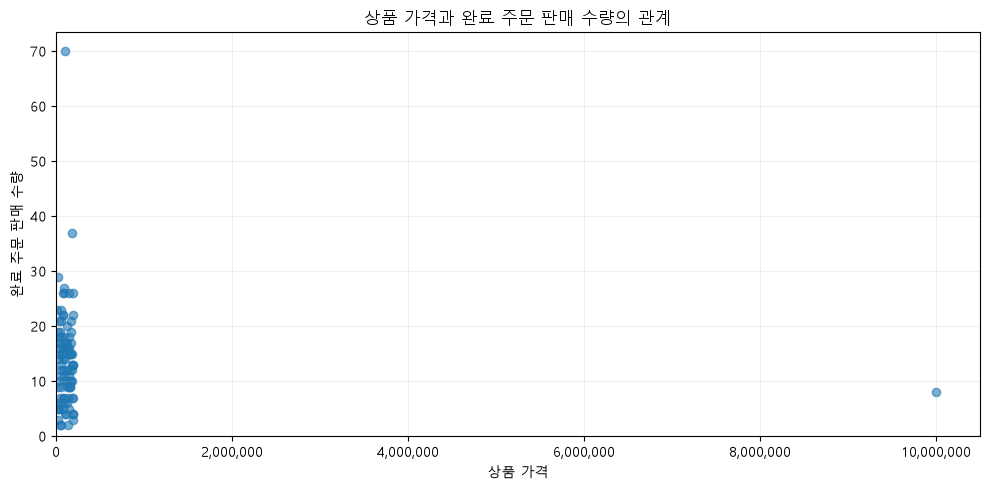

WindowsPath('c:/dev/llm-data-analysis-study/reports/figures/ch07_price_completed_quantity_scatter.png')

In [11]:
scatter_path = plot_price_quantity_scatter(
    product_sales,
    FIGURE_DIR / "ch07_price_completed_quantity_scatter.png",
    show=True,
)
scatter_path

### 그래프 3 기록

- **관찰:** 점들이 어떤 범위에 분포하는가?
- **해석:** 관계가 있어 보이는가, 뚜렷하지 않은가?
- **한계:** 카테고리·할인·노출·재고 등 다른 변수를 확인하지 않은 상태에서 무엇을 말할 수 없는가?
- **다음 질문:** 어떤 변수를 추가하면 관계를 더 잘 이해할 수 있는가?

## 4. 대표 그래프 3
![대표 그래프 3](images/graph03.png)

### 원본 집계값
| 항목 | 값 |
| --- | --- |
| mean | 2.048958e+05 |
| std | 1.011848e+06 |
| min | 5.000000e+03 |
| 25% | 5.275000e+04 |
| 50% | 9.450000e+04 |
| 75% | 1.532500e+05 |
| max | 9.999999e+06 |

### 결과 관찰
히스토그램으로 시각화한 결과 극단적인 값이 하나 존재해 튀어 보이게 나타났다.

### 나의 해석과 판단
극단적인 값 하나 떄문에 나머지 값들의 분포를 시각적으로 알기 어렵다. 따라서 시각화 시 극단적인 값을 제외하고 히스토그램을 그린 후, 극단적인 값이 존재함을 따로 표기하는 편이 나을 거 같다.

### 업무·분석적 의미
전체 분포상 극단적인 값이 포함되어 있으므로, 상품 가격 기입에 오류가 존재할 가능성이 존재한다. 따라서 실제 존재하는 가격인지 학인할 필요가 있다.

### 한계와 추가 확인 사항
극단적인 값을 제외하고 새 히스토그램을 그려볼 필요가 있다.

## 7. 완료 주문 구매 금액 상위 고객 — 익명 가로 막대그래프

공개 그래프에서는 고객 이름이나 원본 고객 ID를 직접 표시하지 않고 **순위 기반 익명 라벨**을 사용합니다. Top 10은 전체 고객 분포가 아니라 일부 고객만 보여 줍니다.

In [12]:
from src.visualization import plot_top_customers

customer_sales[
    ["customer_id", "completed_order_count", "completed_amount", "average_completed_order_amount"]
].head(10)

,customer_id,completed_order_count,completed_amount,average_completed_order_amount
1,3,3,6702000.0,2234000.0
7,14,4,5122000.0,1280500.0
56,90,3,4311000.0,1437000.0
46,65,6,3977000.0,662833.0
65,104,2,3966000.0,1983000.0
58,93,4,3845000.0,961250.0
11,20,4,3808000.0,952000.0
27,38,4,3656000.0,914000.0
19,28,4,3201000.0,800250.0
54,85,4,2832000.0,708000.0


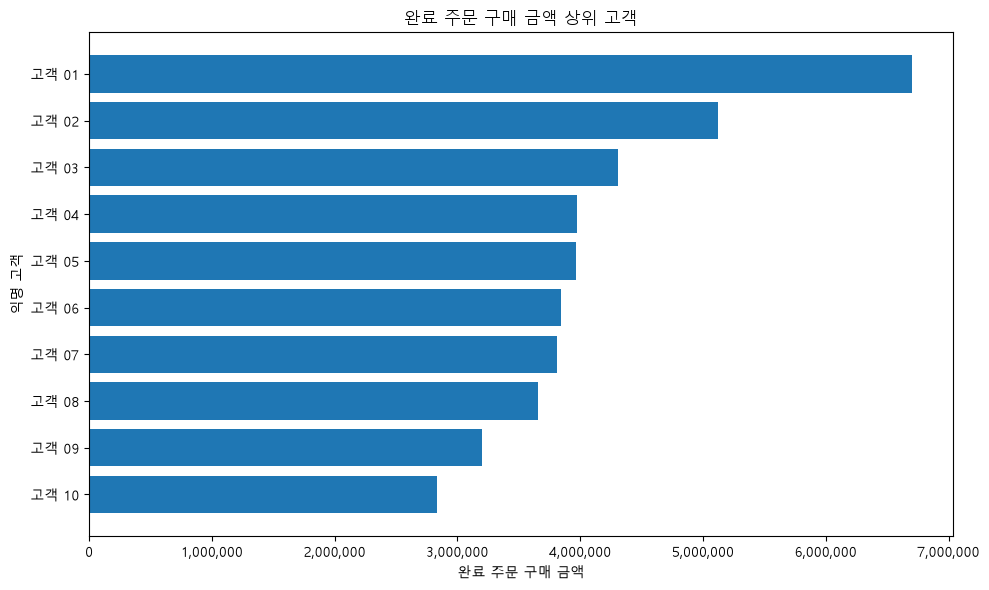

WindowsPath('c:/dev/llm-data-analysis-study/reports/figures/ch07_top_customers_anonymized_barh.png')

In [13]:
top_customer_path = plot_top_customers(
    customer_sales,
    FIGURE_DIR / "ch07_top_customers_anonymized_barh.png",
    show=True,
    top_n=10,
)
top_customer_path

### 해석 주의

구매 금액이 높다고 바로 '충성 고객'이라고 부르지 않습니다.

- 반복 주문 횟수는 많은가?
- 한 번의 큰 주문 때문인가?
- 평균 주문 금액은 어떤가?
- 분석 기간이 충분한가?

## 8. 전체 주문 상태 — 막대그래프

이 그래프만 전체 주문을 사용합니다. 상태별 규모는 보여 주지만 취소·환불의 원인을 설명하지 않습니다.

In [14]:
from src.visualization import plot_order_status

order_status

,order_status,order_count
0,completed,178
1,cancelled,63
2,refunded,56


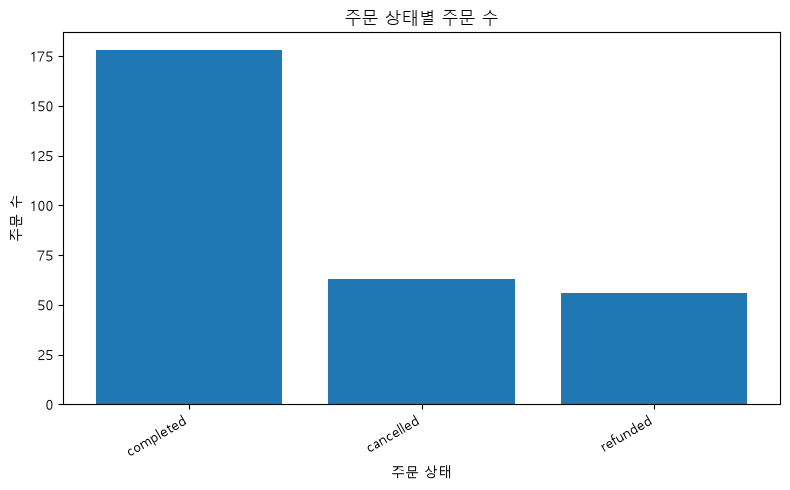

WindowsPath('c:/dev/llm-data-analysis-study/reports/figures/ch07_order_status_bar.png')

In [15]:
order_status_path = plot_order_status(
    order_status,
    FIGURE_DIR / "ch07_order_status_bar.png",
    show=True,
)
order_status_path

## 9. 그래프와 숫자를 교차 검증합니다

대표 그래프 3개 이상에 대해 다음을 확인합니다.

```text
그래프에 표시된 값
=
그래프 원본 집계표의 값
```

또한 다음을 점검합니다.

- 축 이름과 단위가 맞는가?
- 범주 정렬과 날짜 정렬이 맞는가?
- 막대그래프 값 축이 불필요하게 잘리지 않았는가?
- 제목이 실제 분석 범위를 반영하는가?
- 데이터가 없는 구간을 임의로 0으로 만들지 않았는가?

## 5. 그래프 정확성 점검
- [O] 그래프 값과 집계표 값 일치
- [O] 축 이름 확인
- [O] 단위 확인
- [O] 범례 확인
- [O] 날짜 정렬 확인
- [O] 과장될 수 있는 축 범위 확인
- [O] 제목이 분석 범위를 정확히 표현

### 내가 발견한 시각화 위험 또는 개선점
금액대 별 상품 분포에 있어 극단적인 값 때문에 분포가 왜곡 되어 있다. 따라서 시각화에 있어 극단적인 값을 제외할 필요가 있다.

## 10. 공통 함수로 전체 그래프와 보고서를 다시 생성합니다

Notebook에서 개별 그래프를 이해한 뒤 공통 함수를 사용해 같은 결과를 재현합니다.

In [ ]:
from src.visualization import (
    build_visualization_report,
    create_all_figures,
    create_visualization_summary,
)

saved_figures = create_all_figures(viz_data, FIGURE_DIR, show=False)
summary = create_visualization_summary()

summary_path = REPORT_DIR / "ch07_visualization_summary.md"
summary_path.write_text(
    build_visualization_report(summary),
    encoding="utf-8",
)

print("생성 파일")
for path in saved_figures:
    print("-", path)

print("요약 보고서:", summary_path)
summary

생성 파일
- c:\dev\llm-data-analysis-study\reports\figures\ch07_category_completed_amount_bar.png
- c:\dev\llm-data-analysis-study\reports\figures\ch07_monthly_completed_amount_line.png
- c:\dev\llm-data-analysis-study\reports\figures\ch07_product_price_hist.png
- c:\dev\llm-data-analysis-study\reports\figures\ch07_price_completed_quantity_scatter.png
- c:\dev\llm-data-analysis-study\reports\figures\ch07_top_customers_anonymized_barh.png
- c:\dev\llm-data-analysis-study\reports\figures\ch07_order_status_bar.png
요약 보고서: c:\dev\llm-data-analysis-study\reports\ch07_visualization_summary.md


,chart,question,scope,interpretation_point,file_name
0,카테고리별 완료 주문 금액,카테고리별 완료 주문 금액은 어떻게 다른가?,completed orders,금액 차이는 수량·단가 등 추가 지표로 확인,ch07_category_completed_amount_bar.png
1,월별 완료 주문 금액,월별 완료 주문 금액은 어떻게 변하는가?,completed orders + valid order_date,증감은 관찰이며 원인은 추가 데이터 필요,ch07_monthly_completed_amount_line.png
2,상품 가격 분포,상품 가격은 어떤 구간에 몰려 있는가?,product master,상품 구성 분포이며 판매 선호를 의미하지 않음,ch07_product_price_hist.png
3,상품 가격과 완료 주문 판매 수량,상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?,completed orders aggregated by product,관계는 인과를 의미하지 않음,ch07_price_completed_quantity_scatter.png
4,완료 주문 구매 금액 상위 고객,완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?,completed orders aggregated by customer,Top N이며 충성도를 자동 의미하지 않음,ch07_top_customers_anonymized_barh.png
5,주문 상태별 주문 수,주문 상태별 주문 수는 어떻게 다른가?,all orders,상태 분포만으로 취소·환불 원인을 알 수 없음,ch07_order_status_bar.png


: 

## 11. Chapter 07 최종 판단

아래 내용을 직접 작성합니다.

### 가장 중요한 그래프 1개와 이유
가격대별 상품 분포-극단적이 값이 있음을 확인해 이상치 여부를 확인해봐야하기 떄문이다.

### 그래프에서 직접 확인한 사실
극단적으로 비싼 가격의 상품이 하나 존재한다.

### 내가 해석한 내용
이상치일 것이다. 일반적으로 쇼핑몰에서 판매할 가격이 아니다. 따라서 이상치 처리를 진행해야한다. 실제 가격을 확인해 진위를 파악해야한다.

### 그래프만으로 말할 수 없는 것
이상치라고 확정 지을 수는 없다. 판매 목적이 아닌 입력용으로 둔 상품일 수 있기 때문이다. 그러나 이경우, 실제 판매 목적이 아니므로 분석에서 제외해야한다.

### 오해를 줄이기 위해 수정하거나 확인한 요소
- 축: 각 축이 무엇을 의미하는지가 제대로 드러나는지 확인하였다.
- 단위: 원래의 raw 상에도 금액의 단위가 명시되어 있지않아 생략하였다.
- 정렬: 요일의 경우 월요일이 가장 먼저 오도록, 월의 경우 시기가 가장 빠른 달이 먼저 오도록 설정하였다.
- 범위: 구간 설정이 이상치 값에 의해 큰 영향을 주지 못했다.
- 개인정보: 고객 주문 금액 순위를 매길 때, 고객의 이름을 사용하지 않고 익명으로 표기하였다.

### 다음 분석에서 확인하고 싶은 질문
정말 금액 분포에서 가장 비싼 가격은 이상치일까?

월별 완료 주문 기준 카테고리별 매출 비교.
---

## 완료 체크

- [O] 질문을 그래프보다 먼저 정했습니다.
- [O] 금액성 그래프에 `completed` 주문 범위를 적용했습니다.
- [O] 집계 검증표의 `passed`를 확인했습니다.
- [O] 대표 그래프 3개 이상을 만들었습니다.
- [O] 그래프와 원본 집계값을 교차 확인했습니다.
- [O] 축·단위·정렬·범위를 확인했습니다.
- [O] 관계를 원인으로 단정하지 않았습니다.
- [O] 고객 그래프에서 개인정보를 직접 노출하지 않았습니다.
- [O] 그래프별 관찰·해석·한계·다음 질문을 작성했습니다.
- [O] `reports/figures`와 요약 보고서가 재생성되는지 확인했습니다.

다음 Chapter 08에서는 전처리, EDA, 시각화와 보고서를 하나의 작은 분석 프로젝트로 연결합니다.

## 6. Chapter 07 최종 판단
### 가장 중요한 그래프 1개와 이유
가격대별 상품 분포-극단적이 값이 있음을 확인해 이상치 여부를 확인해봐야하기 떄문이다.

### 그래프가 보여 준 사실
극단적으로 비싼 가격의 상품이 하나 존재한다.

### 그래프만으로 말할 수 없는 것
이상치라고 확정 지을 수는 없다. 판매 목적이 아닌 입력용으로 둔 상품일 수 있기 때문이다. 그러나 이경우, 실제 판매 목적이 아니므로 분석에서 제외해야한다.

### 다음 분석에서 확인할 질문
정말 금액 분포에서 가장 비싼 가격은 이상치일까?

월별 완료 주문 기준 카테고리별 매출 비교.

## 최종 체크
- [O] 그래프와 수치를 교차 검증했습니다.
- [O] 관찰과 해석을 구분했습니다.
- [O] 업무적 의미와 한계를 작성했습니다.
- [O] 최종 Notebook URL을 제출합니다.